# Aplicación 2 — Finanzas: series de tiempo con LSTM

**Objetivo:** aprender a modelar series financieras con redes recurrentes y, sobre todo, a evaluarlas con honestidad.

Hay un hecho empírico central en finanzas cuantitativas:

> Los **retornos** de un activo son casi impredecibles, pero su **volatilidad** (la magnitud de los movimientos)
> sí es predecible, porque se agrupa en el tiempo: a días turbulentos les siguen días turbulentos.

En este notebook lo comprobamos con dos experimentos usando la misma arquitectura LSTM:

1. Predecir la **dirección** del retorno de mañana → esperamos ~50 % (azar).
2. Predecir la **volatilidad** de la próxima semana → la red sí aprende algo útil y supera a un modelo ingenuo.

Usamos un mercado **simulado con un modelo GARCH(1,1)**, el modelo clásico de volatilidad (Bollerslev, 1986). La
ventaja es que conocemos la volatilidad "verdadera" y podemos medir qué tan cerca está la red del óptimo teórico.
Al final hay una celda para repetir todo con precios reales.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. Simular un mercado con GARCH(1,1)

El retorno logarítmico diario es $r_t = \sigma_t \, \varepsilon_t$, donde $\varepsilon_t$ sigue una t de Student
(colas pesadas, como en los mercados reales) y la varianza evoluciona como

$$\sigma_t^2 = \omega + \alpha\, r_{t-1}^2 + \beta\, \sigma_{t-1}^2 .$$

Un retorno grande hoy ($r_{t-1}^2$ alto) aumenta la varianza de mañana: eso es el *agrupamiento de volatilidad*.

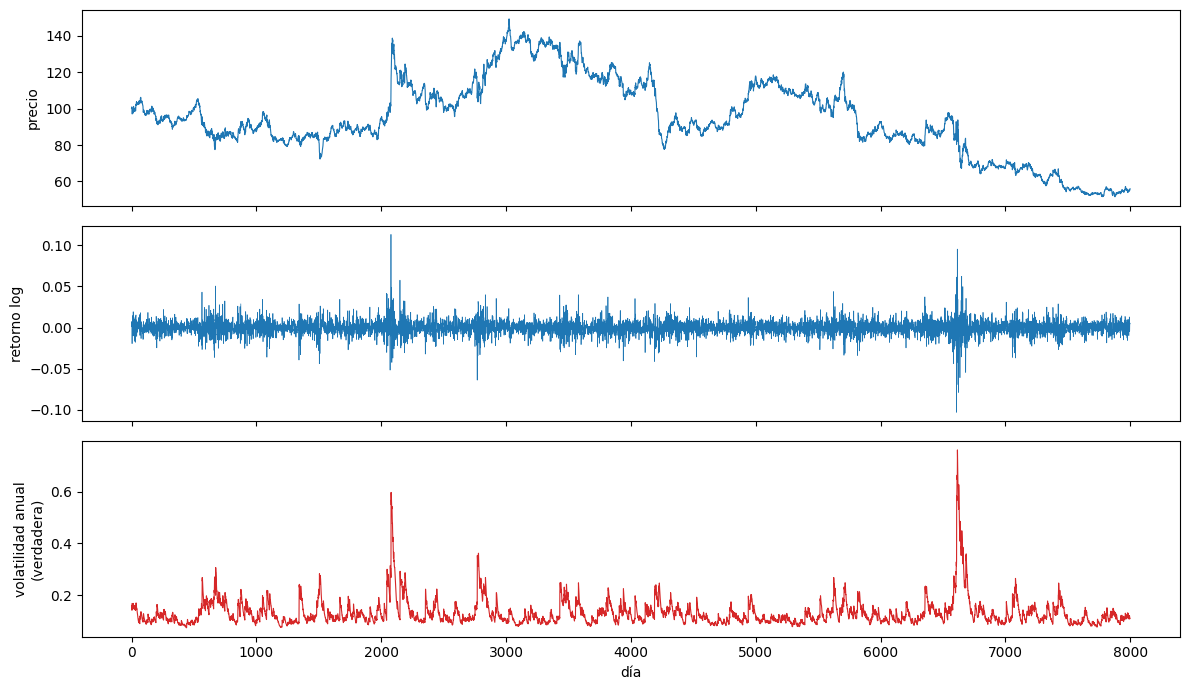

In [2]:
def simulate_garch(n, omega=2e-6, alpha=0.09, beta=0.89, dof=5, seed=0):
    rng = np.random.default_rng(seed)
    eps = rng.standard_t(dof, size=n) / np.sqrt(dof / (dof - 2))   # varianza unitaria
    sigma2 = np.empty(n)
    r = np.empty(n)
    sigma2[0] = omega / (1 - alpha - beta)
    r[0] = np.sqrt(sigma2[0]) * eps[0]
    for t in range(1, n):
        sigma2[t] = omega + alpha * r[t - 1] ** 2 + beta * sigma2[t - 1]
        r[t] = np.sqrt(sigma2[t]) * eps[t]
    return r, np.sqrt(sigma2)

N_DAYS = 8000                         # ~32 años de días hábiles
returns, true_sigma = simulate_garch(N_DAYS)
price = 100 * np.exp(np.cumsum(returns))

fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
ax[0].plot(price, lw=0.8); ax[0].set_ylabel("precio")
ax[1].plot(returns, lw=0.5); ax[1].set_ylabel("retorno log")
ax[2].plot(true_sigma * np.sqrt(252), lw=0.8, color="C3"); ax[2].set_ylabel("volatilidad anual\n(verdadera)")
ax[2].set_xlabel("día")
plt.tight_layout(); plt.show()

### Hechos estilizados

- La **autocorrelación de los retornos** es prácticamente cero → el pasado no dice nada sobre la dirección.
- La **autocorrelación de $|r_t|$** es positiva y decae lentamente → el pasado sí informa sobre la magnitud.

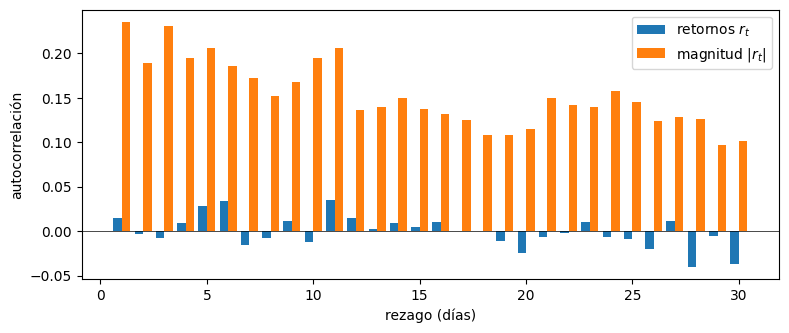

In [3]:
def autocorr(x, max_lag=30):
    x = x - x.mean()
    return np.array([np.corrcoef(x[:-k], x[k:])[0, 1] for k in range(1, max_lag + 1)])

lags = np.arange(1, 31)
plt.figure(figsize=(9, 3.5))
plt.bar(lags - 0.2, autocorr(returns), width=0.4, label="retornos $r_t$")
plt.bar(lags + 0.2, autocorr(np.abs(returns)), width=0.4, label="magnitud $|r_t|$")
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("rezago (días)"); plt.ylabel("autocorrelación"); plt.legend(); plt.show()

## 2. Construir ventanas y dividir **cronológicamente**

Error muy común: mezclar aleatoriamente los días antes de separar train/test. Eso filtra información del futuro
(*look-ahead bias*). En series de tiempo siempre se divide por fecha: 70 % pasado para entrenar, 15 % para
validar y el 15 % más reciente para la prueba final. La normalización se calcula **solo** con train.

Cada ejemplo es una ventana de los últimos `WINDOW` días con dos características por día: $r_t$ y $|r_t|$.

Objetivos:
- `y_dir`: 1 si el retorno de mañana es positivo.
- `y_vol`: logaritmo de la volatilidad realizada en los próximos 5 días, $\log \sqrt{\tfrac{1}{5}\sum_{k=1}^{5} r_{t+k}^2}$.

In [4]:
WINDOW, HORIZON = 60, 5
scale = 100.0                                   # trabajar en "puntos porcentuales"

feats = np.stack([returns, np.abs(returns)], axis=1) * scale
X, y_dir, y_vol, sigma_next = [], [], [], []
for t in range(WINDOW, N_DAYS - HORIZON):
    X.append(feats[t - WINDOW:t])
    future = returns[t:t + HORIZON]
    y_dir.append(float(returns[t] > 0))
    y_vol.append(np.log(np.sqrt(np.mean(future ** 2)) * scale))
    sigma_next.append(true_sigma[t:t + HORIZON])
X = np.array(X, dtype=np.float32)
y_dir = np.array(y_dir, dtype=np.float32)
y_vol = np.array(y_vol, dtype=np.float32)
sigma_next = np.array(sigma_next)

n = len(X)
i_train, i_val = int(0.70 * n), int(0.85 * n)
mu, sd = X[:i_train].reshape(-1, 2).mean(0), X[:i_train].reshape(-1, 2).std(0)
Xn = (X - mu) / sd

def split(arr):
    return arr[:i_train], arr[i_train:i_val], arr[i_val:]

print("ejemplos train/val/test:", [len(a) for a in split(Xn)])

ejemplos train/val/test: [5554, 1190, 1191]


## 3. El modelo: LSTM + capa lineal

Una LSTM lee la ventana día a día y resume la historia en su estado oculto final; una capa lineal produce la
predicción. Usaremos exactamente la misma clase para ambos experimentos.

In [5]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_features=2, hidden=32, layers=1, dropout=0.0):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=layers, batch_first=True, dropout=dropout)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.lstm(x)              # out: [batch, tiempo, hidden]
        return self.head(out[:, -1]).squeeze(-1)

def train_model(y, loss_fn, epochs=30, lr=1e-3):
    torch.manual_seed(0)
    model = LSTMForecaster().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    (Xtr, Xva, _), (ytr, yva, _) = split(Xn), split(y)
    dl = DataLoader(TensorDataset(torch.tensor(Xtr), torch.tensor(ytr)), batch_size=128, shuffle=True)
    Xva_t, yva_t = torch.tensor(Xva).to(device), torch.tensor(yva).to(device)
    best, best_state, curve = float("inf"), None, []
    for epoch in range(epochs):
        model.train()
        for xb, yb in dl:
            loss = loss_fn(model(xb.to(device)), yb.to(device))
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            val = loss_fn(model(Xva_t), yva_t).item()
        curve.append(val)
        if val < best:                     # early stopping: guardamos el mejor modelo en validación
            best, best_state = val, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, curve

def predict(model, Xs):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(Xs).to(device)).cpu().numpy()

## 4. Experimento A — ¿Sube o baja mañana?

In [6]:
dir_model, dir_curve = train_model(y_dir, F.binary_cross_entropy_with_logits, epochs=15)
_, _, Xte = split(Xn)
_, _, yte_dir = split(y_dir)
acc = ((predict(dir_model, Xte) > 0) == yte_dir).mean()
print(f"Exactitud LSTM en test:                {acc:.3f}")
print(f"Predecir siempre la clase mayoritaria: {max(yte_dir.mean(), 1 - yte_dir.mean()):.3f}")

Exactitud LSTM en test:                0.515
Predecir siempre la clase mayoritaria: 0.515


Como era de esperar, la LSTM no supera de forma significativa a predecir siempre la clase mayoritaria. Por
construcción, en este mercado los retornos no tienen información direccional; en mercados reales ocurre algo muy
parecido. **Si un modelo de dirección te da 70 % de exactitud, lo primero es buscar una fuga de información.**

## 5. Experimento B — ¿Qué tan volátil será la próxima semana?

Comparamos contra dos referencias:
- **Ingenua (histórica):** la volatilidad de los últimos 20 días.
- **Oráculo GARCH:** la volatilidad verdadera de la simulación (inalcanzable en la práctica; nos dice cuál es el
  mejor error posible dado el ruido intrínseco).

In [7]:
vol_model, vol_curve = train_model(y_vol, F.mse_loss, epochs=30)

_, _, yte_vol = split(y_vol)
pred_lstm = predict(vol_model, Xte)
raw_te = split(X)[2][:, :, 0] / scale                                    # retornos sin normalizar
pred_naive = np.log(np.sqrt(np.mean(raw_te[:, -20:] ** 2, axis=1)) * scale)
pred_oracle = np.log(np.sqrt(np.mean(split(sigma_next)[2] ** 2, axis=1)) * scale)
# El oráculo predice E[sigma]; el log de la vol. realizada tiene un sesgo negativo que corregimos con train
bias = np.mean(split(y_vol)[0] - np.log(np.sqrt(np.mean(split(sigma_next)[0] ** 2, axis=1)) * scale))
pred_oracle = pred_oracle + bias

def mse(p): return np.mean((p - yte_vol) ** 2)
for name, p in [("Ingenua (20 días)", pred_naive), ("LSTM", pred_lstm), ("Oráculo GARCH", pred_oracle)]:
    print(f"{name:18s} MSE = {mse(p):.4f}")

Ingenua (20 días)  MSE = 0.2566
LSTM               MSE = 0.2200
Oráculo GARCH      MSE = 0.1759


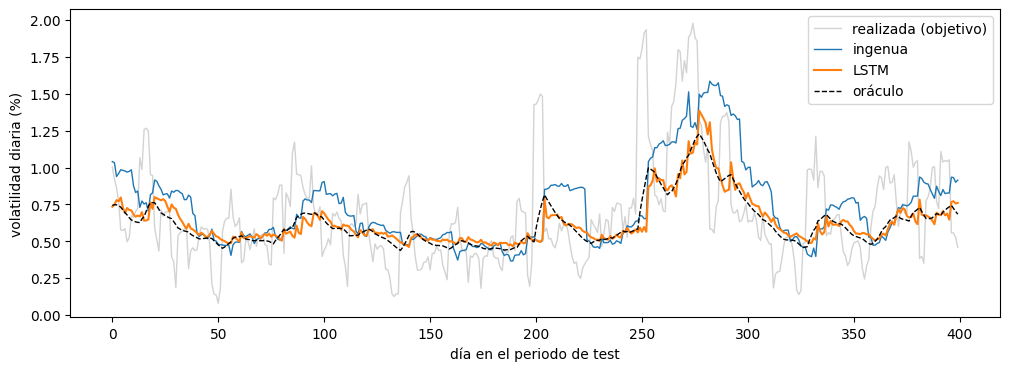

In [8]:
seg = slice(0, 400)
plt.figure(figsize=(12, 4))
plt.plot(np.exp(yte_vol[seg]), color="lightgray", lw=1, label="realizada (objetivo)")
plt.plot(np.exp(pred_naive[seg]), lw=1, label="ingenua")
plt.plot(np.exp(pred_lstm[seg]), lw=1.5, label="LSTM")
plt.plot(np.exp(pred_oracle[seg]), lw=1, ls="--", color="k", label="oráculo")
plt.ylabel("volatilidad diaria (%)"); plt.xlabel("día en el periodo de test"); plt.legend(); plt.show()

La LSTM aprende la dinámica de agrupamiento de volatilidad a partir de los datos (sin conocer la ecuación GARCH)
y supera a la regla ingenua, cerrando buena parte de la brecha con el oráculo. La brecha restante es el
margen de mejora: más datos, mejores características o arquitecturas distintas (ver ejercicios). Este tipo de pronóstico es útil para
**gestión de riesgo** (VaR, *position sizing*) y para **valoración de opciones**.

## 6. Con datos reales (opcional)

Requiere `pip install yfinance` y conexión a internet. Reemplaza `returns` y vuelve a ejecutar desde la sección 2
(sin `true_sigma` no hay oráculo; omite esa línea).

```python
import yfinance as yf
px = yf.download("SPY", start="2000-01-01", auto_adjust=True)["Close"].squeeze()
returns = np.log(px).diff().dropna().values
N_DAYS = len(returns)
```

**Ejercicios**
1. Agrega como característica el volumen o un índice de volatilidad (VIX) y mide si mejora el pronóstico.
2. Cambia la LSTM por un `nn.TransformerEncoder` o una CNN 1D causal. ¿Cuál gana con 60 días de ventana?
3. Usa la volatilidad predicha para escalar una posición (*volatility targeting*) y compara el Sharpe ratio contra
   mantener una posición fija.
4. Implementa una validación *walk-forward* (reentrenar cada año) en lugar de un único corte.